Saving IM-0005-0001.jpeg to IM-0005-0001.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

🩻 Image: IM-0005-0001.jpeg
📌 Prediction: NORMAL (0.78 confidence)


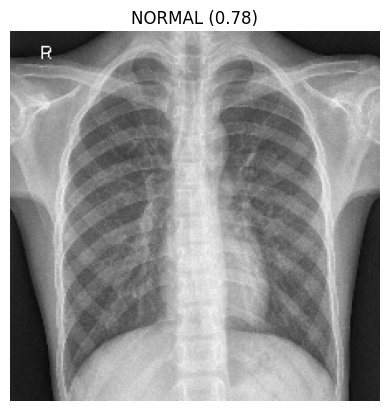

In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from google.colab import files

# Load your trained model
model = tf.keras.models.load_model('/content/drive/MyDrive/pneumonia_detector_model.h5', compile=False)

# Class names
class_names = ['NORMAL', 'PNEUMONIA']
preprocess_input_fn = tf.keras.applications.efficientnet.preprocess_input

# Upload an image from your computer
uploaded = files.upload()

# Predict each uploaded image
for filename in uploaded.keys():
    img_path = filename
    img = image.load_img(img_path, target_size=(224, 224)).convert('RGB')
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input_fn(img_array)

    prediction = model.predict(img_array)[0][0]
    label = class_names[int(prediction > 0.5)]
    confidence = prediction if prediction > 0.5 else 1 - prediction

    # Show prediction and image
    print(f"\n🩻 Image: {filename}")
    print(f"📌 Prediction: {label} ({confidence:.2f} confidence)")

    plt.imshow(img)
    plt.title(f"{label} ({confidence:.2f})")
    plt.axis('off')
    plt.show()